# Class weights, threshold tuning and calibration (issue #15)

Question for the business: **which engines should the team inspect first, and how many?**

Model: `HistGradientBoostingClassifier` with the tuned settings from #10 (all tuned boosters tie on AUC, about 0.70, so we use the fastest one; the conclusions here do not depend on this choice).

Rules: development data only (train + val). Predictions for every dev row come from **out-of-fold** models (each row is scored by a model that never saw it), so threshold choices are not made on training data. The test set is not touched.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

from src.common import load_dev, evaluate, RANDOM_STATE, ROOT
warnings.filterwarnings('ignore')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

X, y = load_dev()
yv = y.values
PARAMS = dict(l2_regularization=8.5689, learning_rate=0.04048, max_iter=406, max_leaf_nodes=14,
              min_samples_leaf=30, early_stopping=True, random_state=RANDOM_STATE)
OOF_CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
prev = yv.mean()
print(X.shape, 'prevalence', round(prev, 3))

(16604, 6) prevalence 0.631


## 1. Class weights

Does re-weighting the classes help? It shifts predicted probabilities, so it mainly changes thresholded metrics; ranking quality (AUC) should barely move. Logged with the shared protocol.

In [2]:
rows = [evaluate(HistGradientBoostingClassifier(**PARAMS), X, y, name='HistGB tuned, no class weights',
                 params={'class_weight': None}, notes='#15'),
        evaluate(HistGradientBoostingClassifier(class_weight='balanced', **PARAMS), X, y, name='HistGB tuned, class_weight=balanced',
                 params={'class_weight': 'balanced'}, notes='#15')]
pd.DataFrame(rows)[['model', 'cv_auc_mean', 'cv_auc_std', 'cv_pr_auc_mean', 'cv_f1_mean', 'cv_recall_mean', 'cv_precision_mean']]

,model,cv_auc_mean,cv_auc_std,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean
0,"HistGB tuned, no class weights",0.7004,0.0092,0.7977,0.7610,0.8371,0.6977
1,"HistGB tuned, class_weight=balanced",0.7001,0.0087,0.7974,0.6797,0.6100,0.7678


## 2. Out-of-fold probabilities and calibration

Is a predicted probability of 0.7 really right 70% of the time? Compared: raw model, sigmoid (Platt) and isotonic calibration, each calibrated inside the training folds.

Brier of always predicting the prevalence: 0.233


,AUC,Brier,LogLoss
raw,0.6994,0.2067,0.5987
sigmoid,0.7009,0.2064,0.5979
isotonic,0.7001,0.2066,0.6002


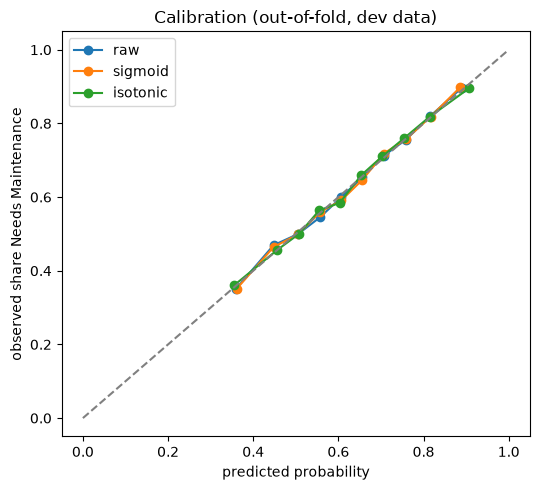

In [3]:
def oof(model):
    return cross_val_predict(model, X, y, cv=OOF_CV, method='predict_proba', n_jobs=-1)[:, 1]

p_raw = oof(HistGradientBoostingClassifier(**PARAMS))
p_sig = oof(CalibratedClassifierCV(HistGradientBoostingClassifier(**PARAMS), method='sigmoid', cv=3))
p_iso = oof(CalibratedClassifierCV(HistGradientBoostingClassifier(**PARAMS), method='isotonic', cv=3))
cal = pd.DataFrame({name: {'AUC': roc_auc_score(yv, p), 'Brier': brier_score_loss(yv, p), 'LogLoss': log_loss(yv, p)}
                    for name, p in [('raw', p_raw), ('sigmoid', p_sig), ('isotonic', p_iso)]}).T
print('Brier of always predicting the prevalence:', round(prev * (1 - prev), 4))
display(cal.round(4))

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in [('raw', p_raw), ('sigmoid', p_sig), ('isotonic', p_iso)]:
    frac, mean = calibration_curve(yv, p, n_bins=10, strategy='quantile')
    ax.plot(mean, frac, marker='o', label=name)
ax.plot([0, 1], [0, 1], '--', c='gray'); ax.set_xlabel('predicted probability'); ax.set_ylabel('observed share Needs Maintenance')
ax.set_title('Calibration (out-of-fold, dev data)'); ax.legend(); plt.tight_layout()
plt.savefig(FIG / 'calibration.png', dpi=130); plt.show()

## 3. Threshold trade-off

The default threshold 0.5 is not special. Because 63% of engines are positive, flagging everyone gives recall 1.0 and precision 0.63; the model only helps if it raises precision at a useful recall.

,flagged_%,precision,recall,specificity,F1,balanced_acc
threshold,,,,,,
0.40,91.863,0.656,0.955,0.144,0.778,0.550
0.45,84.751,0.674,0.906,0.253,0.773,0.580
0.50,76.024,0.697,0.840,0.376,0.762,0.608
0.55,66.454,0.721,0.760,0.498,0.740,0.629
0.60,56.360,0.750,0.670,0.619,0.708,0.645
0.65,46.127,0.779,0.570,0.724,0.658,0.647
0.70,36.377,0.805,0.465,0.808,0.589,0.636
0.75,26.716,0.833,0.353,0.879,0.496,0.616
0.80,17.387,0.866,0.239,0.937,0.375,0.588


Best balanced accuracy at threshold 0.65


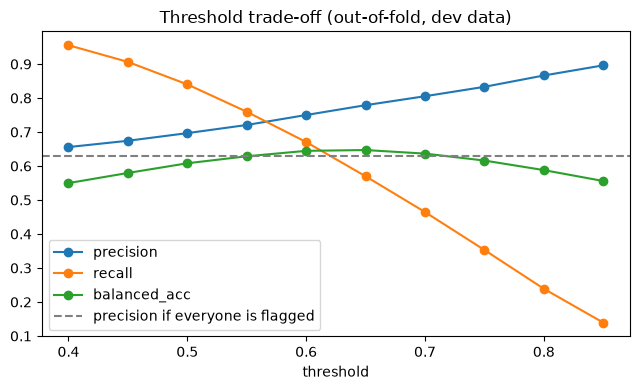

In [4]:
def at_threshold(p, t):
    pred = p >= t
    tp = (pred & (yv == 1)).sum(); fp = (pred & (yv == 0)).sum(); fn = (~pred & (yv == 1)).sum(); tn = (~pred & (yv == 0)).sum()
    prec = tp / max(tp + fp, 1); rec = tp / (tp + fn); spec = tn / (tn + fp)
    return {'threshold': t, 'flagged_%': 100 * pred.mean(), 'precision': prec, 'recall': rec, 'specificity': spec,
            'F1': 2 * prec * rec / max(prec + rec, 1e-9), 'balanced_acc': (rec + spec) / 2}

ths = np.round(np.arange(0.40, 0.86, 0.05), 2)
tab = pd.DataFrame([at_threshold(p_raw, t) for t in ths]).set_index('threshold')
display(tab.round(3))
best_bal = tab['balanced_acc'].idxmax(); print('Best balanced accuracy at threshold', best_bal)

fig, ax = plt.subplots(figsize=(6.5, 4))
for c in ['precision', 'recall', 'balanced_acc']: ax.plot(tab.index, tab[c], marker='o', label=c)
ax.axhline(prev, ls='--', c='gray', label='precision if everyone is flagged'); ax.set_xlabel('threshold'); ax.legend()
ax.set_title('Threshold trade-off (out-of-fold, dev data)'); plt.tight_layout()
plt.savefig(FIG / 'threshold_tradeoff.png', dpi=130); plt.show()

## 4. Inspect the top k% by risk

Compared with picking engines at random (precision = 63% whatever k is), not with zero.

In [5]:
order = np.argsort(-p_raw); ys = yv[order]
rows = []
for k in (0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.70):
    n = int(len(ys) * k); prec = ys[:n].mean()
    rows.append({'inspect_top_%': int(k * 100), 'precision': prec, 'lift_vs_random': prec / prev,
                 'share_of_all_faults_caught_%': 100 * ys[:n].sum() / ys.sum()})
topk = pd.DataFrame(rows).set_index('inspect_top_%'); display(topk.round(3))

,precision,lift_vs_random,share_of_all_faults_caught_%
inspect_top_%,,,
5,0.930,1.475,7.374
10,0.896,1.422,14.213
20,0.858,1.361,27.223
30,0.824,1.307,39.211
40,0.796,1.263,50.501
50,0.768,1.218,60.885
70,0.712,1.129,79.043


## 5. Cost view: when does the model beat "inspect everything"?

Costs are **assumptions** (no cost data in the dataset). Let one unneeded inspection cost 1 unit and one missed fault cost `r` units. Per engine, expected cost = (false alarms x 1 + misses x r) / n. Two no-model options: *inspect all* (cost = share of healthy engines) and *inspect none* (cost = r x share of faulty engines). The model must beat both.

In [6]:
def cost_at(p, t, r):
    pred = p >= t
    fp = (pred & (yv == 0)).sum(); fn = (~pred & (yv == 1)).sum()
    return (fp + r * fn) / len(yv)

grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
rows = []
for r in (1, 2, 3, 5, 10):
    costs = [cost_at(p_raw, t, r) for t in grid]
    j = int(np.argmin(costs))
    all_c, none_c = (1 - prev), r * prev
    rows.append({'miss_cost_r': r, 'best_threshold': grid[j], 'model_cost': costs[j], 'inspect_all': all_c,
                 'inspect_none': none_c, 'saving_vs_best_no_model_%': 100 * (min(all_c, none_c) - costs[j]) / min(all_c, none_c),
                 'flagged_%': 100 * (p_raw >= grid[j]).mean()})
cost = pd.DataFrame(rows).set_index('miss_cost_r'); display(cost.round(3))
cost.round(4).to_csv(ROOT / 'reports' / 'cost_sensitivity.csv')

,best_threshold,model_cost,inspect_all,inspect_none,saving_vs_best_no_model_%,flagged_%
miss_cost_r,,,,,,
1,0.50,0.331,0.369,0.631,10.318,76.024
2,0.34,0.364,0.369,1.261,1.369,97.001
3,0.28,0.369,0.369,1.892,0.065,99.566
5,0.20,0.369,0.369,3.153,0.016,99.994
10,0.20,0.369,0.369,6.305,0.016,99.994


## 6. Conclusions

- **Class weights** do not help ranking (AUC 0.7004 vs 0.7001). `balanced` only moves the operating point (recall 0.84 -> 0.61, precision 0.70 -> 0.77). The same trade-off is available by changing the threshold, so we keep unweighted training and choose the threshold afterwards.
- **Calibration:** the raw boosting probabilities are already well calibrated (Brier 0.2067; sigmoid 0.2064; isotonic 0.2066; constant-prevalence baseline 0.233). Calibration adds nothing.
- **Threshold:** 0.5 flags 76% of engines (recall 0.84, precision 0.70). Balanced accuracy peaks around 0.60 to 0.65 (flags 46% to 56%; recall 0.57 to 0.67, precision 0.75 to 0.78).
- **Top-k inspection:** the top 10% by risk has 90% precision, but random picking already gives 63%: lift is only 1.4x at 10% and 1.2x at 50%.
- **Cost view (assumed costs):** the model beats "inspect everything" only when a missed fault costs about the same as an unneeded inspection (r = 1: 10% cheaper at threshold 0.50). From r = 2 upward the cheapest policy is to inspect almost every engine; the model saves 1% or less.

**Business reading:** with 63% of engines labelled "Needs Maintenance" and AUC about 0.70, the model gives a modest prioritisation gain, not a way to avoid most inspections. This is a limit of the data (weak signal, unknown label definition), not of the boosting algorithm. Re-check with real cost figures if the team can get them.